<a href="https://colab.research.google.com/github/Rohan46os/Video_gen_model/blob/main/diffusion_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import kagglehub
path = kagglehub.dataset_download("andrewmvd/face-mask-detection")

100%|██████████| 398M/398M [00:10<00:00, 38.2MB/s]

Extracting files...


In [6]:
path

'/root/.cache/kagglehub/datasets/andrewmvd/face-mask-detection/versions/1'

In [7]:
img1_path = "/root/.cache/kagglehub/datasets/andrewmvd/face-mask-detection/versions/1/images/maksssksksss1.png"

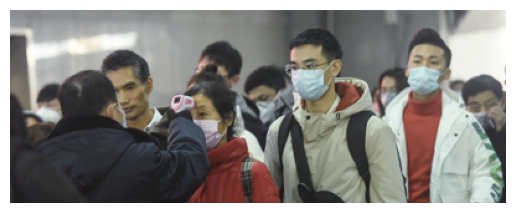

In [8]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(img1_path)

plt.imshow(img)
plt.axis("off")
plt.show()

In [10]:
from tqdm import tqdm
import os
import numpy as np
from PIL import Image

image_folder = "/root/.cache/kagglehub/datasets/andrewmvd/face-mask-detection/versions/1/images"

vectors = []
filenames = []

files = os.listdir(image_folder)

for filename in tqdm(files):
    filepath = os.path.join(image_folder, filename)

    try:
        img = Image.open(filepath).convert("RGB")
        img = img.resize((128, 128))

        img_array = np.array(img, dtype=np.float32) / 255.0
        vectors.append(img_array.flatten())
        filenames.append(filename)

    except:
        pass

vectors = np.array(vectors)

print(vectors.shape)

100%|██████████| 853/853 [00:15<00:00, 55.06it/s]


(853, 49152)


In [11]:
import torch

X = torch.tensor(vectors, dtype=torch.float32)

# (N, 49152) → (N, 128, 128, 3)
X = X.reshape(-1, 128, 128, 3)

# (N, H, W, C) → (N, C, H, W)
X = X.permute(0, 3, 1, 2)

print(X.shape)

torch.Size([853, 3, 128, 128])


In [12]:
vectors.shape

(853, 49152)

In [13]:
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(X)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

In [14]:
dataset

**Now bulding a VAE which will predict MEAN and VARIANCE**

Building a cnn VAE encoder which predicts the mean and variance of all the vectors


In [15]:
import torch
import torch.nn as nn


class Encoder(nn.Module):
    def __init__(self, latent_channels=4):
        super().__init__()

        self.encoder = nn.Sequential(
            # [B, 3, 128, 128]
            nn.Conv2d(3, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            # [B, 64, 64, 64]
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            # [B, 128, 32, 32]
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
        )

        # Produce mean and log-variance
        self.mu = nn.Conv2d(
            128, latent_channels,
            kernel_size=3, stride=1, padding=1
        )

        self.logvar = nn.Conv2d(
            128, latent_channels,
            kernel_size=3, stride=1, padding=1
        )

    def forward(self, x):
        h = self.encoder(x)

        mu = self.mu(h)
        logvar = self.logvar(h)

        return mu, logvar

In [16]:
model = Encoder()

x = torch.randn(32, 3, 128, 128)

mu, logvar = model(x)

print("input   :", x.shape) # (32, 49152)
print("mu      :", mu.shape) #(32, 4096)
print("logvar  :", logvar.shape) #(32, 4096)

input   : torch.Size([32, 3, 128, 128])
mu      : torch.Size([32, 4, 32, 32])
logvar  : torch.Size([32, 4, 32, 32])


In [17]:
std  =torch.randn_like(logvar*5) #

z = mu + torch.exp(logvar/2)*torch.randn_like(logvar) # these are latent vecors of inputs


print(z.shape)

torch.Size([32, 4, 32, 32])


logvar

   ↓
   
  exp()

variance

   ↓

  sqrt()

standard deviation

   ↓

μ + σ ε

   ↓

z

In [18]:

std.shape

torch.Size([32, 4, 32, 32])

In [75]:
T = 200

betas = torch.linspace(1e-4, 0.02, T)
alphas = (1-betas)
alpha_bar = torch.cumprod(alphas, dim=0)
epsilon = torch.randn_like(z)

t = torch.randint(0, T, (z.shape[0],)) # for 32 diffirent values you select 32 different time steps

alpha_bar_t = alpha_bar[t].view(-1, 1, 1, 1)

z_t = (
    torch.sqrt(alpha_bar_t) * z
    + torch.sqrt(1 - alpha_bar_t) * epsilon
)


In [76]:
print("Initial alpha_bar:", alpha_bar[0].item())
print("Final alpha_bar:", alpha_bar[-1].item())

Initial alpha_bar: 0.9998999834060669
Final alpha_bar: 0.1321827620267868


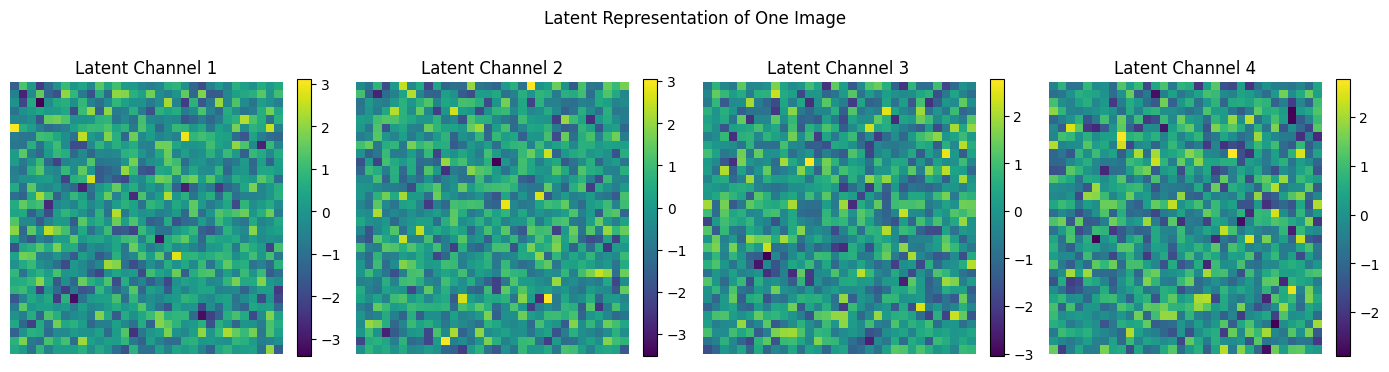

In [77]:
import matplotlib.pyplot as plt
import torch

# Take the first image in the batch
latent = z[0].detach().cpu()

fig, axes = plt.subplots(1, latent.shape[0], figsize=(14, 4))

for i in range(latent.shape[0]):
    im = axes[i].imshow(latent[i], cmap="viridis")
    axes[i].set_title(f"Latent Channel {i + 1}")
    axes[i].axis("off")
    plt.colorbar(im, ax=axes[i], fraction=0.046)

plt.suptitle("Latent Representation of One Image")
plt.tight_layout()
plt.show()

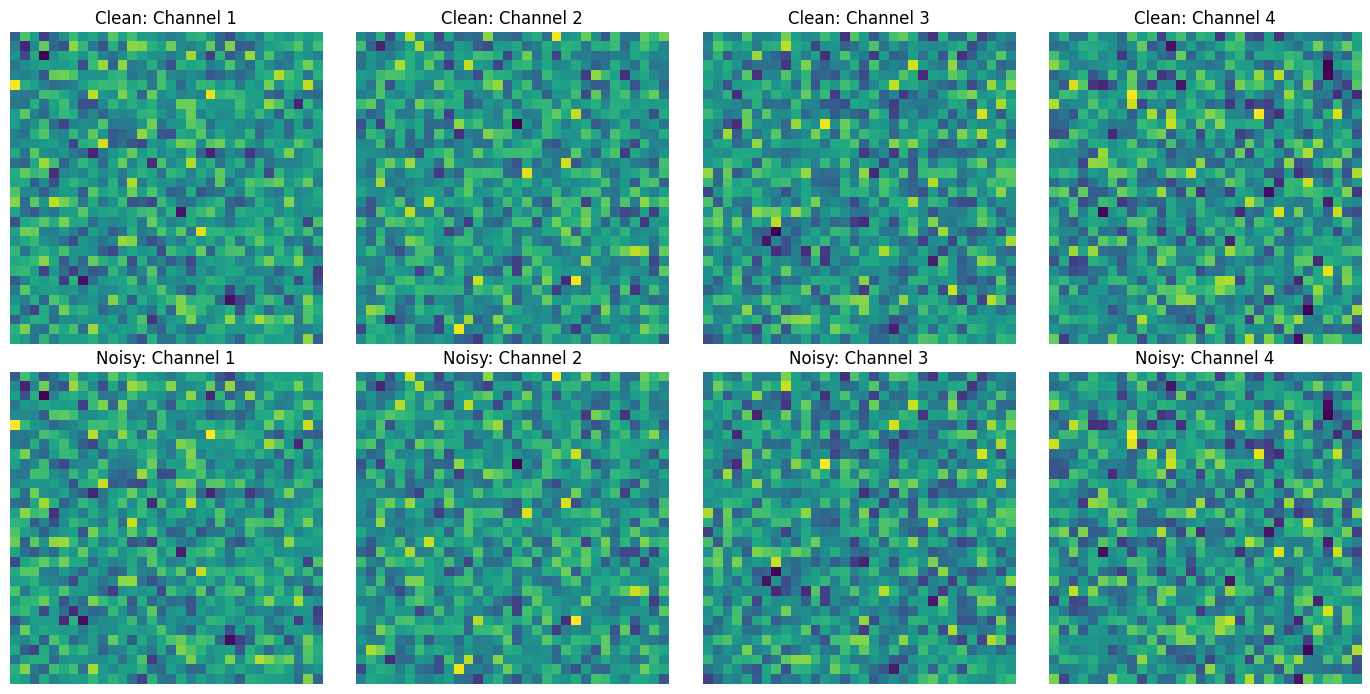

In [78]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

z0 = z[0].detach().cpu()
zt = z_t[0].detach().cpu()

# Use the same color scale for each corresponding channel
for i in range(4):
    vmin = min(z0[i].min().item(), zt[i].min().item())
    vmax = max(z0[i].max().item(), zt[i].max().item())

    axes[0, i].imshow(z0[i], cmap="viridis", vmin=vmin, vmax=vmax)
    axes[0, i].set_title(f"Clean: Channel {i+1}")

    axes[1, i].imshow(zt[i], cmap="viridis", vmin=vmin, vmax=vmax)
    axes[1, i].set_title(f"Noisy: Channel {i+1}")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()